In [1]:
import os, re, glob, json, time, warnings, platform, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
from boruta import BorutaPy

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

In [2]:
# CONFIG 
SEED = 42
FAST_MODE = False            # True = tiny caps / grids for debugging only (results are NOT representative)

DATA_DIR   = Path("../data/raw")                    # the 8 CICIDS2017 "MachineLearningCVE" csv files
CACHE_FILE = DATA_DIR / "merged_raw_v2.parquet"     # v2 cache = includes the extra 'day' column
SRC_DIR    = Path("../src")
MODELS_DIR = Path("../models")
CONFIG_DIR = Path("../configs")
EXP_DIR    = Path("../experiments")
for d in (SRC_DIR, MODELS_DIR, CONFIG_DIR, EXP_DIR, EXP_DIR / "figures"):
    d.mkdir(parents=True, exist_ok=True)

N_JOBS = -1
SEEDS  = [42, 43, 44, 45, 46]                       

# Operating points: every threshold below is chosen on VALIDATION data only
FPR_BUDGETS = {"FPR<=3%": 0.03, "FPR<=1%": 0.01, "FPR<=0.1%": 0.001 }    
DEPLOY_OP   = "FPR<=3%"                            

# Proposal acceptance criteria 
TARGETS = {"precision": 0.85, "recall": 0.80, "f1": 0.80, "fpr_max": 0.03, "latency_ms": 5.0}

# Feature-selection sample + Boruta
SEL_BENIGN_N, SEL_PER_CLASS_CAP, BORUTA_MAX_ITER, BORUTA_TREES = 60_000, 15_000, 50, 100

# Isolation Forest search space
MS_GRID    = [256, 1024, 4096, 16384, 65536, 262144, 0.9612]   # max_samples 
AP_TOL     = 0.98                                              # pick the smallest max_samples reaching >= 98% of the best val AP
N_EST_GRID = [100, 200]
MF_GRID    = [0.6, 0.8, 1.0]
RF_PARAMS  = dict(n_estimators=150, min_samples_leaf=2, max_samples=0.2, class_weight="balanced_subsample")
RUN_TEMPORAL_CHECK = True                                      # train on Mon-Wed, test on Thu-Fri (unseen attack families)

if FAST_MODE:
    SEEDS = [42, 43, 44]
    SEL_BENIGN_N, SEL_PER_CLASS_CAP, BORUTA_MAX_ITER, BORUTA_TREES = 15_000, 3_000, 20, 60
    MS_GRID = [256, 1024, 4096, 16384, 0.9612]
    N_EST_GRID, MF_GRID = [50, 100], [0.8, 1.0]
    RF_PARAMS.update(n_estimators=60)

print(f"sklearn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__} | python {platform.python_version()}")

sklearn 1.9.1 | pandas 3.0.6 | numpy 2.4.6 | python 3.11.16


In [3]:
import sys, importlib
sys.path.insert(0, str(Path("..").resolve()))
(SRC_DIR / "__init__.py").touch(exist_ok=True)

import src.IF_preprocess as ids_pp
importlib.reload(ids_pp)                       # safe when this cell is re-run
from src.IF_preprocess import FlowPreprocessor, IFDetector, signed_log1p, anomaly_confidence

# Data loading and Cleaning
the weekday is parsed from the **file name** and kept as a `day` column (needed for the per-day and
temporal analyses), and duplicates are defined on *features + label* only (not on `day`).

In [4]:
def load_raw(data_dir: Path, cache_file: Path) -> pd.DataFrame:
    if cache_file.exists():
        print("Loading cached merged data (v2)...")
        return pd.read_parquet(cache_file)
    print("First run: reading and merging the CSV files...")
    files = sorted(glob.glob(str(data_dir / "*.csv")))
    assert files, f"No CSV files found in {data_dir.resolve()}"
    frames = []
    for f in files:
        part = pd.read_csv(f, encoding="latin1", low_memory=False)     # the Thursday file contains a cp1252 en-dash
        part.columns = part.columns.str.strip().str.lower()
        m = re.search(r"(monday|tuesday|wednesday|thursday|friday)", os.path.basename(f).lower())
        part["day"] = m.group(1) if m else "unknown"
        frames.append(part)
    out = pd.concat(frames, ignore_index=True)
    out.to_parquet(cache_file, index=False)
    return out

df = load_raw(DATA_DIR, CACHE_FILE)
assert "day" in df.columns, "Delete the old parquet cache - it was created without the 'day' column"
print(f"Data successfully loaded! Shape: {df.shape}")
df.info()

Loading cached merged data (v2)...
Data successfully loaded! Shape: (2830743, 80)
<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 80 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   destination port             int64  
 1   flow duration                int64  
 2   total fwd packets            int64  
 3   total backward packets       int64  
 4   total length of fwd packets  int64  
 5   total length of bwd packets  int64  
 6   fwd packet length max        int64  
 7   fwd packet length min        int64  
 8   fwd packet length mean       float64
 9   fwd packet length std        float64
 10  bwd packet length max        int64  
 11  bwd packet length min        int64  
 12  bwd packet length mean       float64
 13  bwd packet length std        float64
 14  flow bytes/s                 float64
 15  flow packets/s               float64
 16  flow iat mean                float64
 17  flow iat std 

In [5]:
# (+-inf replaced only for this summary - they are handled explicitly further below)
df.replace([np.inf, -np.inf], np.nan).describe().T

,count,mean,std,min,25%,50%,75%,max
destination port,2830743.0,8.071483e+03,1.828363e+04,0.0,53.0,80.0,443.0,65535.0
flow duration,2830743.0,1.478566e+07,3.365374e+07,-13.0,155.0,31316.0,3204828.5,119999998.0
total fwd packets,2830743.0,9.361160e+00,7.496728e+02,1.0,2.0,2.0,5.0,219759.0
total backward packets,2830743.0,1.039377e+01,9.973883e+02,0.0,1.0,2.0,4.0,291922.0
total length of fwd packets,2830743.0,5.493024e+02,9.993589e+03,0.0,12.0,62.0,187.0,12900000.0
...,...,...,...,...,...,...,...,...
active min,2830743.0,5.829582e+04,5.770923e+05,0.0,0.0,0.0,0.0,110000000.0
idle mean,2830743.0,8.316037e+06,2.363008e+07,0.0,0.0,0.0,0.0,120000000.0
idle std,2830743.0,5.038439e+05,4.602984e+06,0.0,0.0,0.0,0.0,76900000.0
idle max,2830743.0,8.695752e+06,2.436689e+07,0.0,0.0,0.0,0.0,120000000.0


In [6]:
# Normalise labels (the "Web Attack <dash> X" names contain a broken character in the raw files)
df["label"] = (df["label"].astype(str).str.strip()
                 .str.replace(r"Web Attack\s*\W+\s*", "Web Attack - ", regex=True))

label_counts = df["label"].value_counts()
label_pct = (label_counts / len(df) * 100).round(3)
display(pd.concat({"count": label_counts, "pct": label_pct}, axis=1))
print("Days:", df["day"].value_counts().to_dict())

,count,pct
label,,
BENIGN,2273097,80.300
DoS Hulk,231073,8.163
PortScan,158930,5.614
DDoS,128027,4.523
DoS GoldenEye,10293,0.364
FTP-Patator,7938,0.280
SSH-Patator,5897,0.208
DoS slowloris,5796,0.205
DoS Slowhttptest,5499,0.194


Days: {'friday': 703245, 'wednesday': 692703, 'monday': 529918, 'thursday': 458968, 'tuesday': 445909}


In [7]:
# ---- Duplicates (analysed per class, then removed BEFORE splitting so no identical row lands in train and test) ----
FEATURE_COLS_ALL = [c for c in df.columns if c not in ("label", "day")]
dup_mask = df.duplicated(subset=FEATURE_COLS_ALL + ["label"])
print(f"Total duplicated rows: {dup_mask.sum():,} ({dup_mask.mean():.2%})")

dup_report = (df.assign(is_dup=dup_mask).groupby("label")["is_dup"]
                .agg(total="size", duplicates="sum"))
dup_report["dup_%"] = (dup_report["duplicates"] / dup_report["total"] * 100).round(2)
display(dup_report.sort_values("total", ascending=False))

df_clean = df.loc[~dup_mask].copy()
assert not df_clean.duplicated(subset=FEATURE_COLS_ALL + ["label"]).any()
print(f"Rows before: {len(df):,} | after dedup: {len(df_clean):,}")

Total duplicated rows: 308,381 (10.89%)


,total,duplicates,dup_%
label,,,
BENIGN,2273097,176613,7.77
DoS Hulk,231073,58224,25.20
PortScan,158930,68111,42.86
DDoS,128027,11,0.01
DoS GoldenEye,10293,7,0.07
FTP-Patator,7938,2005,25.26
SSH-Patator,5897,2678,45.41
DoS slowloris,5796,411,7.09
DoS Slowhttptest,5499,271,4.93


Rows before: 2,830,743 | after dedup: 2,522,362


> Deduplication changes the class mix (PortScan lost ~43%, DoS Hulk ~25%, BENIGN only ~8%). That is intentional but must be
> stated in the report: the prevalence and the difficulty of the task change.

In [8]:
def inspect_inf_and_nan(frame: pd.DataFrame, cols) -> pd.DataFrame:
    """Per-column count of +-inf and NaN values (non-numeric strings are coerced to NaN first)."""
    rows = []
    for c in cols:
        s = pd.to_numeric(frame[c], errors="coerce")
        n_inf, n_nan = int(np.isinf(s).sum()), int(s.isna().sum())
        if n_inf or n_nan:
            rows.append({"column": c, "n_inf": n_inf, "n_nan": n_nan})
    return pd.DataFrame(rows)

numeric_cols = [c for c in df_clean.columns if c not in ("label", "day")]
display(inspect_inf_and_nan(df_clean, numeric_cols))

df_clean[numeric_cols] = df_clean[numeric_cols].apply(pd.to_numeric, errors="coerce")
df_clean[numeric_cols] = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
corrupted_mask = df_clean[numeric_cols].isna().any(axis=1)

,column,n_inf,n_nan
0,flow bytes/s,1211,353
1,flow packets/s,1564,0


In [9]:
# Loss per class BEFORE dropping the corrupted rows (v1 logic kept)
loss = pd.DataFrame({"total": df_clean["label"].value_counts(),
                     "dropped": df_clean.loc[corrupted_mask, "label"].value_counts()}).fillna(0).astype(int)
loss["loss_%"] = (loss["dropped"] / loss["total"] * 100).round(3)
display(loss.sort_values("dropped", ascending=False))

df_clean = df_clean.loc[~corrupted_mask].reset_index(drop=True)
print(f"Rows after dropping inf/NaN rows: {len(df_clean):,}")

,total,dropped,loss_%
label,,,
BENIGN,2096484,1427,0.068
PortScan,90819,125,0.138
Bot,1953,5,0.256
DoS Hulk,172849,3,0.002
DDoS,128016,2,0.002
FTP-Patator,5933,2,0.034
DoS GoldenEye,10286,0,0.000
DoS slowloris,5385,0,0.000
DoS Slowhttptest,5228,0,0.000


Rows after dropping inf/NaN rows: 2,520,798


> The rows are dropped here **for research only**. In production the same inf/NaN values cannot be dropped:
> `FlowPreprocessor` replaces them with the train medians, so the serving path never fails on them.

In [10]:
# Audit of negative values: physically impossible for most of these columns (CICFlowMeter overflow / -1 sentinels)
neg_rows = []
for c in numeric_cols:
    n_neg = int((df_clean[c] < 0).sum())
    if n_neg:
        neg_rows.append({"column": c, "n_negative": n_neg, "pct": round(n_neg / len(df_clean) * 100, 4), "min": df_clean[c].min()})
display(pd.DataFrame(neg_rows).sort_values("n_negative", ascending=False) if neg_rows else "no negative values")

,column,n_negative,pct,min
11,init_win_bytes_backward,1215625,48.2238,-1.000000e+00
10,init_win_bytes_forward,911012,36.1398,-1.000000e+00
5,flow iat min,2880,0.1142,-1.400000e+01
2,flow packets/s,107,0.0042,-2.000000e+06
0,flow duration,107,0.0042,-1.300000e+01
3,flow iat mean,107,0.0042,-1.300000e+01
4,flow iat max,107,0.0042,-1.300000e+01
1,flow bytes/s,78,0.0031,-2.610000e+08
7,fwd header length,35,0.0014,-3.221223e+10
9,fwd header length.1,35,0.0014,-3.221223e+10


> keeps the sign (`signed_log1p`), so the model can still see that these flows are unusual.

# splitting

70 / 15 / 15, **stratified on the attack family** (not stratifing on the binary label only), so rare families
(Heartbleed, SQLi, Infiltration) appear in every split and per-family recall can be reported.

In [11]:
if FAST_MODE:   # debugging only: (NOT representative of the real prevalence)
    parts = [g.sample(min(len(g), 20_000 if lab == "BENIGN" else 5_000), random_state=SEED)
             for lab, g in df_clean.groupby("label")]
    df_clean = pd.concat(parts)
    print(f"FAST_MODE: using {len(df_clean):,} rows")

y = (df_clean["label"].str.upper() != "BENIGN").astype(int)

# Sanity check before dropping the duplicated header-length column
print("fwd header length == fwd header length.1:", df_clean["fwd header length"].equals(df_clean["fwd header length.1"]))

# 'destination port' is a shortcut feature (specific ports <-> specific attacks) and hurts generalisation
cols_to_drop = ["label", "day", "destination port", "fwd header length.1"]
X = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])
meta = df_clean[["label", "day"]]
print(f"X: {X.shape} | attack share: {y.mean():.2%}")

fwd header length == fwd header length.1: True
X: (2520798, 76) | attack share: 16.89%


In [12]:
X_trv, X_test, y_trv, y_test, m_trv, m_test = train_test_split(
    X, y, meta, test_size=0.15, random_state=SEED, stratify=meta["label"])
X_train, X_val, y_train, y_val, m_train, m_val = train_test_split(
    X_trv, y_trv, m_trv, test_size=0.15 / 0.85, random_state=SEED, stratify=m_trv["label"])
del X_trv, y_trv, m_trv

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"Attack share  train/val/test: {y_train.mean():.2%} / {y_val.mean():.2%} / {y_test.mean():.2%}")
split_counts = pd.concat({"train": m_train["label"].value_counts(), "val": m_val["label"].value_counts(),
                          "test": m_test["label"].value_counts()}, axis=1).fillna(0).astype(int)
display(split_counts.sort_values("train", ascending=False))

Train: (1764558, 76) | Val: (378120, 76) | Test: (378120, 76)
Attack share  train/val/test: 16.89% / 16.89% / 16.89%


,train,val,test
label,,,
BENIGN,1466539,314259,314259
DoS Hulk,120992,25927,25927
DDoS,89610,19202,19202
PortScan,63486,13604,13604
DoS GoldenEye,7200,1543,1543
FTP-Patator,4151,890,890
DoS slowloris,3769,808,808
DoS Slowhttptest,3660,784,784
SSH-Patator,2253,483,483


# Feature Selection

<!-- (**Pearson redundancy → Mutual Information → Boruta**, `strict` / `relaxed`), with three fixes:

1. everything runs in **signed-log space** – Pearson and kNN-based MI are dominated by outliers on raw CICFlowMeter data;
2. the selection sample is **family-balanced** (capped per family) so rare attacks can influence the selected features;
3. the result is stored as plain text in `configs/features.json` (v1 depended on a pickle that nobody else had).

A third candidate, `pearson_all` (only the label-free Pearson filter), is kept to test whether the *label-informed*
selection really helps – the model is semi-supervised, not unsupervised. -->

In [13]:
def to_log_space(frame: pd.DataFrame) -> pd.DataFrame:
    """signed log1p on every column (selection stage only)."""
    return pd.DataFrame(signed_log1p(frame.to_numpy()), columns=frame.columns, index=frame.index)


def make_selection_sample(X_, y_, meta_, benign_n, per_class_cap, seed):
    """Family-balanced sample: BENIGN capped at benign_n rows, every attack family capped at per_class_cap rows."""
    local = np.random.default_rng(seed)
    picked = []
    for fam, idx in meta_.groupby("label").groups.items():
        idx = np.asarray(idx)
        cap = benign_n if str(fam).upper() == "BENIGN" else per_class_cap
        picked.append(idx if len(idx) <= cap else local.choice(idx, size=cap, replace=False))
    sel_idx = np.concatenate(picked)
    return X_.loc[sel_idx], y_.loc[sel_idx]


def remove_pearson_redundant_features(X_data: pd.DataFrame, threshold=0.9):
    """Drop constant columns, then for every pair with |corr| > threshold drop the later column."""
    constant = X_data.columns[X_data.nunique() <= 1].tolist()
    X_data = X_data.drop(columns=constant)
    corr = X_data.corr(method="pearson").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if (upper[c] > threshold).any()]
    print(f"Pearson > {threshold}: constant dropped = {len(constant)} | redundant dropped = {len(to_drop)} | kept = {X_data.shape[1] - len(to_drop)}")
    return X_data.drop(columns=to_drop), constant + to_drop


def run_mi_boruta_feature_selection(X_data, y_data, mode="strict", mi_threshold=0.1, min_features=8,
                                    max_iter=50, rf_trees=100, seed=42):
    """MI filter -> Boruta confirmation. strict: alpha=0.01, perc=100 | relaxed: half MI threshold, alpha=0.1, perc=80, + tentative."""
    mi = pd.Series(mutual_info_classif(X_data, y_data, random_state=seed), index=X_data.columns).sort_values(ascending=False)
    thr = mi_threshold if mode == "strict" else mi_threshold * 0.5
    mi_passed = mi[mi > thr].index.tolist()
    if len(mi_passed) < min_features:                       # guard: never go below min_features
        mi_passed = mi.head(min_features).index.tolist()
    print(f"[{mode}] MI > {thr:.3f}: {len(mi_passed)} features")

    perc, alpha = (100, 0.01) if mode == "strict" else (80, 0.1)
    # shallow trees (max_depth<=7) are the BorutaPy recommendation: faster and more stable importances
    rf = RandomForestClassifier(n_estimators=rf_trees, max_depth=7, class_weight="balanced", n_jobs=N_JOBS, random_state=seed)
    boruta = BorutaPy(rf, n_estimators="auto", alpha=alpha, perc=perc, max_iter=max_iter, random_state=seed, verbose=0)
    boruta.fit(X_data[mi_passed].to_numpy(), y_data.to_numpy())

    keep = np.array(mi_passed)[boruta.support_].tolist()
    if mode == "relaxed":
        keep = sorted(set(keep) | set(np.array(mi_passed)[boruta.support_weak_].tolist()))
    if len(keep) < min_features:                            # guard: fall back to the top MI features
        keep = mi_passed[:min_features]
    keep = [c for c in mi.index if c in set(keep)]          # order by MI (desc)
    print(f"[{mode}] Boruta kept {len(keep)} features")
    return keep, mi

In [14]:
t0 = time.perf_counter()
X_sel, y_sel = make_selection_sample(X_train, y_train, m_train, SEL_BENIGN_N, SEL_PER_CLASS_CAP, SEED)
X_sel_log = to_log_space(X_sel)
print(f"Selection sample: {X_sel.shape} | attack share {y_sel.mean():.1%}")

X_sel_pearson, dropped_pearson = remove_pearson_redundant_features(X_sel_log, threshold=0.9)
strict_features,  mi_scores = run_mi_boruta_feature_selection(X_sel_pearson, y_sel, "strict",  0.10, max_iter=BORUTA_MAX_ITER, rf_trees=BORUTA_TREES, seed=SEED)
relaxed_features, _         = run_mi_boruta_feature_selection(X_sel_pearson, y_sel, "relaxed", 0.08, max_iter=BORUTA_MAX_ITER, rf_trees=BORUTA_TREES, seed=SEED)
feature_sets = {"strict": strict_features, "relaxed": relaxed_features, "pearson_all": X_sel_pearson.columns.tolist()}
print({k: len(v) for k, v in feature_sets.items()}, f"| {time.perf_counter() - t0:.0f}s")

with open(CONFIG_DIR / "features.json", "w") as f:
    json.dump({"feature_sets": feature_sets, "dropped_by_pearson_or_constant": dropped_pearson,
               "created": dt.datetime.now().isoformat(timespec="seconds")}, f, indent=2)
print("Saved ->", CONFIG_DIR / "features.json")

Selection sample: (128931, 76) | attack share 53.5%
Pearson > 0.9: constant dropped = 8 | redundant dropped = 34 | kept = 34
[strict] MI > 0.100: 22 features
[strict] Boruta kept 22 features
[relaxed] MI > 0.040: 27 features
[relaxed] Boruta kept 27 features
{'strict': 22, 'relaxed': 27, 'pearson_all': 34} | 82s
Saved -> ..\configs\features.json


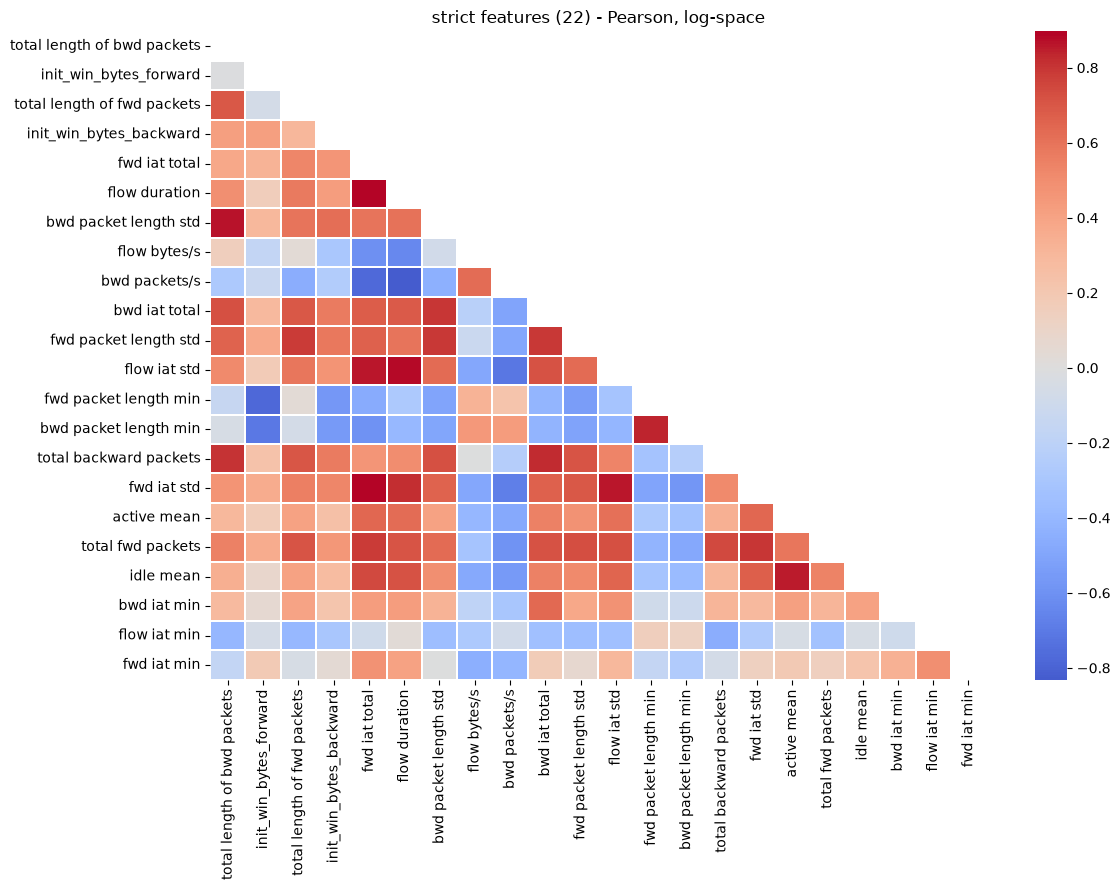

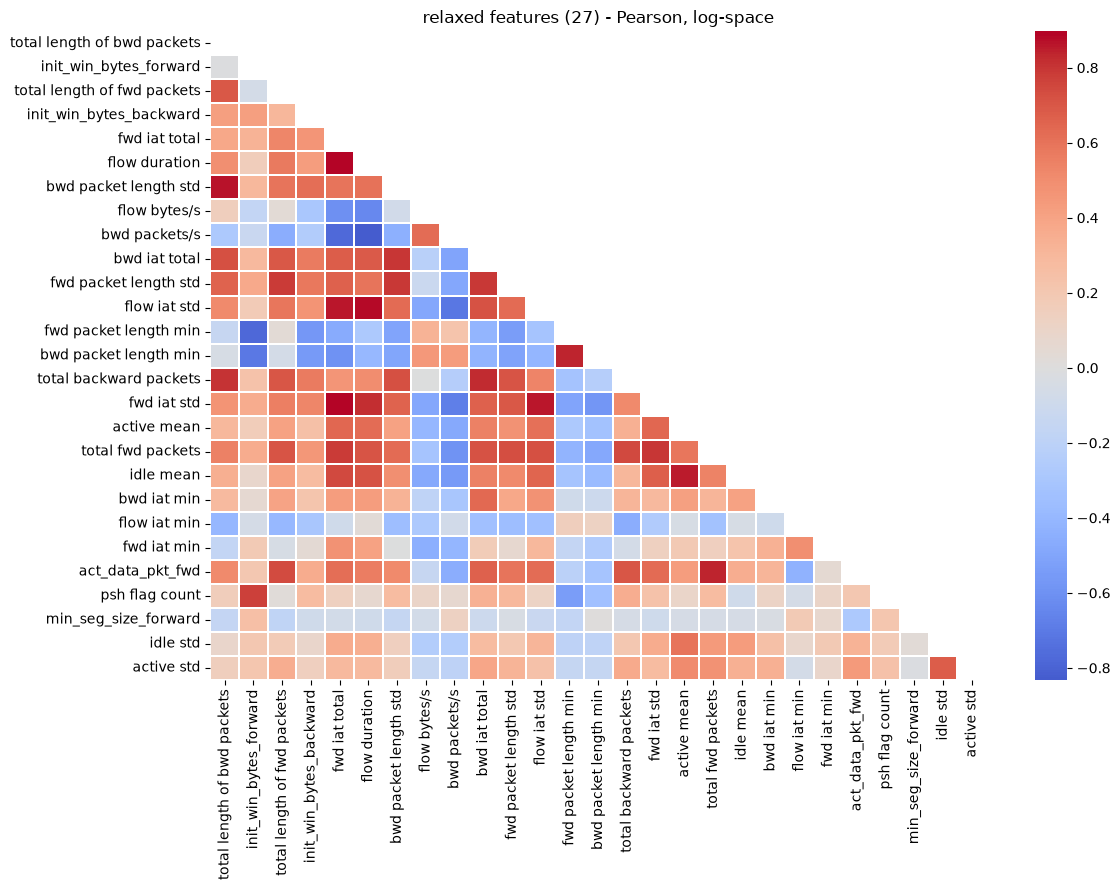

,mutual_information
total length of bwd packets,0.432752
init_win_bytes_forward,0.407811
total length of fwd packets,0.394149
init_win_bytes_backward,0.374871
fwd iat total,0.308520
flow duration,0.290618
bwd packet length std,0.268725
flow bytes/s,0.264078
bwd packets/s,0.254806
bwd iat total,0.236992


In [15]:
def plot_corr_heatmap(frame, title, annot=False):
    corr = frame.corr(method="pearson")
    mask = np.triu(np.ones_like(corr, dtype=bool))
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=annot, fmt=".2f", linewidths=0.2)
    plt.title(title); plt.tight_layout()
    plt.savefig(EXP_DIR / "figures" / f"corr_{title.split()[0].lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_corr_heatmap(X_sel_log[feature_sets["strict"]], f"strict features ({len(feature_sets['strict'])}) - Pearson, log-space")
plot_corr_heatmap(X_sel_log[feature_sets["relaxed"]], f"relaxed features ({len(feature_sets['relaxed'])}) - Pearson, log-space")
display(mi_scores.head(15).rename("mutual_information").to_frame())

# scaling → preprocessing (no scaler, on purpose)

<!-- Isolation Forest chooses split points uniformly between the min and max of a feature, so **any linear scaling
(Standard / MinMax / Robust) produces the same trees**. v1 confirmed it (Log-only 0.8316 vs Log+Robust 0.8302), while
QuantileTransformer (non-linear) lowered F1 to ≤ 0.78. What matters is the **non-linear log** that tames heavy tails
(v1: raw ≈ 0.43–0.55 → log ≈ 0.83). Scalers would only be needed for OCSVM / LOF / autoencoders.

`FlowPreprocessor` is fitted on the training split only: medians and the list of logged columns are learned there. -->

In [16]:
benign_train_mask = (y_train == 0).to_numpy()

# name -> (feature set, use_log). 'strict|raw' is the ablation that shows what the log transform is worth.
VARIANTS = {"strict|log": ("strict", True), "relaxed|log": ("relaxed", True),
            "pearson_all|log": ("pearson_all", True), "strict|raw": ("strict", False)}

PREP, XTR_B, XVA = {}, {}, {}          # the TEST set is deliberately not transformed here
for name, (fs, use_log) in VARIANTS.items():
    prep = FlowPreprocessor(features=feature_sets[fs], log_cols=None if use_log else []).fit(X_train)
    PREP[name] = prep
    XTR_B[name] = prep.transform(X_train.loc[benign_train_mask])     # IF is fitted on BENIGN train only
    XVA[name] = prep.transform(X_val)
    print(f"{name:18s} features={len(prep.features):3d} | logged={len(prep.log_cols_):3d} | benign train {XTR_B[name].shape} | val {XVA[name].shape}")

strict|log         features= 22 | logged= 22 | benign train (1466539, 22) | val (378120, 22)
relaxed|log        features= 27 | logged= 26 | benign train (1466539, 27) | val (378120, 27)
pearson_all|log    features= 34 | logged= 32 | benign train (1466539, 34) | val (378120, 34)
strict|raw         features= 22 | logged=  0 | benign train (1466539, 22) | val (378120, 22)


In [17]:
# Which strict features are log-transformed and why (skew / range audit)
raw_strict = (X_train[feature_sets["strict"]].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan))
audit = pd.DataFrame({"abs_skew": raw_strict.skew().abs().round(1), "min": raw_strict.min(), "max": raw_strict.max(),
                      "logged": raw_strict.columns.isin(PREP["strict|log"].log_cols_)})
display(audit.sort_values("abs_skew", ascending=False))

,abs_skew,min,max,logged
total length of fwd packets,806.1,0.0,1.290000e+07,True
total backward packets,214.9,0.0,2.919220e+05,True
total fwd packets,214.6,1.0,2.197590e+05,True
total length of bwd packets,214.5,0.0,6.554530e+08,True
flow bytes/s,45.9,-261000000.0,2.071000e+09,True
active mean,34.3,0.0,1.100000e+08,True
flow iat min,23.4,-14.0,1.200000e+08,True
bwd packets/s,21.7,0.0,2.000000e+06,True
fwd packet length min,19.4,0.0,2.325000e+03,True
fwd packet length std,10.0,0.0,7.049469e+03,True


# training

<!-- **Protocol:** every decision below uses the **validation** set only – threshold-free metrics (Average Precision, ROC-AUC)
rank the configurations; thresholds are then set by FPR budget. The test set is not loaded into any of these loops.

* **Stage A** – `max_samples` learning curve (is 1.4M rows per tree really needed?)
* **Stage B** – grid over feature set / log-vs-raw / `n_estimators` / `max_features` at the chosen `max_samples`
* **Stage C** – final fit with 5 seeds, then the test set is evaluated once -->

In [18]:
# ----------------------------- evaluation helpers (vectorised) -----------------------------
def anomaly_scores(model, X_):
    """Higher = more anomalous (v1 convention: -decision_function)."""
    return -model.decision_function(X_)


def threshold_at_fpr(y_true, scores, max_fpr):
    """Lowest threshold whose FPR on y_true is <= max_fpr (i.e. highest recall under an FPR budget)."""
    fpr, _, thr = roc_curve(y_true, scores, drop_intermediate=False)
    i = max(np.searchsorted(fpr, max_fpr, side="right") - 1, 0)
    return float(thr[i])


def threshold_max_f1(y_true, scores):
    p, r, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(thr[int(np.argmax(f1))])


def evaluate_pred(y_true, pred):
    y_true = np.asarray(y_true).astype(int); pred = np.asarray(pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"precision": prec, "recall": rec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            "fpr": fp / (fp + tn) if fp + tn else 0.0, "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def evaluate_at(y_true, scores, thr):
    return evaluate_pred(y_true, np.asarray(scores) >= thr)


def operating_thresholds(y_val_, s_val_):
    """All operating points are derived from VALIDATION scores."""
    thr = {"max-F1": threshold_max_f1(y_val_, s_val_)}
    thr.update({op: threshold_at_fpr(y_val_, s_val_, b) for op, b in FPR_BUDGETS.items()})
    return thr


def effective_max_samples(ms, n):
    return int(ms * n) if isinstance(ms, float) else min(int(ms), n)

    
def log_experiment(row):
    row = {"timestamp": dt.datetime.now().isoformat(timespec="seconds"), **row}
    path = EXP_DIR / "results_log.csv"
    pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)

max_samples=     256 | eff=      256 | val AP=0.3605 | AUC=0.8180 | ~1.5 MB | 1s
max_samples=    1024 | eff=    1,024 | val AP=0.4344 | AUC=0.8658 | ~3.7 MB | 1s
max_samples=    4096 | eff=    4,096 | val AP=0.5284 | AUC=0.8958 | ~9.4 MB | 2s
max_samples=   16384 | eff=   16,384 | val AP=0.6161 | AUC=0.9276 | ~24.6 MB | 4s
max_samples=   65536 | eff=   65,536 | val AP=0.7426 | AUC=0.9502 | ~62.5 MB | 5s
max_samples=  262144 | eff=  262,144 | val AP=0.7810 | AUC=0.9468 | ~157.9 MB | 10s
max_samples=  0.9612 | eff=1,409,637 | val AP=0.8391 | AUC=0.9596 | ~539.0 MB | 39s

Chosen max_samples = 0.9612  (smallest value with val AP >= 98% of the best 0.8391)


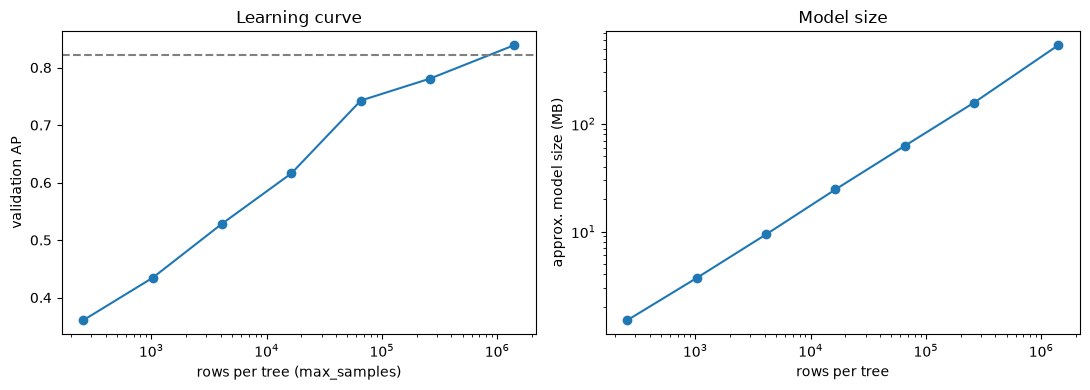

In [19]:
# ----------------------- Stage A: max_samples learning curve (strict|log, validation only) -----------------------
Xb, Xv = XTR_B["strict|log"], XVA["strict|log"]
curve_rows, ms_used = [], []
for ms in MS_GRID:
    if isinstance(ms, int) and ms > len(Xb):
        continue                                           # larger than the benign train set
    t0 = time.perf_counter()
    model = IsolationForest(n_estimators=100, max_samples=ms, max_features=1.0, contamination="auto",
                            random_state=SEED, n_jobs=N_JOBS).fit(Xb)
    fit_s = time.perf_counter() - t0
    s_val = anomaly_scores(model, Xv)
    nodes = sum(e.tree_.node_count for e in model.estimators_)
    curve_rows.append({"eff_samples": effective_max_samples(ms, len(Xb)),
                       "val_ap": average_precision_score(y_val, s_val), "val_auc": roc_auc_score(y_val, s_val),
                       "fit_s": round(fit_s, 1), "approx_MB": round(nodes * 96 / 1e6, 1)})
    ms_used.append(ms)
    log_experiment({"stage": "A_learning_curve", "variant": "strict|log", "max_samples": str(ms), **curve_rows[-1]})
    print(f"max_samples={str(ms):>8} | eff={curve_rows[-1]['eff_samples']:>9,} | val AP={curve_rows[-1]['val_ap']:.4f} | AUC={curve_rows[-1]['val_auc']:.4f} | ~{curve_rows[-1]['approx_MB']} MB | {fit_s:.0f}s")
    del model

curve = pd.DataFrame(curve_rows)
best_ap = curve["val_ap"].max()
chosen_pos = int(curve.index[curve["val_ap"] >= AP_TOL * best_ap][0])          # rows are in ascending eff_samples order
BEST_MS = ms_used[chosen_pos]
print(f"\nChosen max_samples = {BEST_MS}  (smallest value with val AP >= {AP_TOL:.0%} of the best {best_ap:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(curve["eff_samples"], curve["val_ap"], "o-"); ax[0].axhline(AP_TOL * best_ap, ls="--", c="gray")
ax[0].set(xlabel="rows per tree (max_samples)", ylabel="validation AP", title="Learning curve")
ax[1].loglog(curve["eff_samples"], curve["approx_MB"], "o-"); ax[1].set(xlabel="rows per tree", ylabel="approx. model size (MB)", title="Model size")
plt.tight_layout(); plt.savefig(EXP_DIR / "figures" / "max_samples_curve.png", dpi=150); plt.show()

In [20]:
# ----------------------- Stage B: grid at the chosen max_samples (validation only) -----------------------
# Runtime note: this is len(VARIANTS) x len(grid) fits. If BEST_MS is large (e.g. 0.9612) shrink N_EST_GRID / MF_GRID in the config cell.
grid = list(ParameterGrid({"n_estimators": N_EST_GRID, "max_features": MF_GRID}))
rows = []
for vname in VARIANTS:
    Xb, Xv = XTR_B[vname], XVA[vname]
    for params in grid:
        t0 = time.perf_counter()
        model = IsolationForest(**params, max_samples=BEST_MS, contamination="auto", random_state=SEED, n_jobs=N_JOBS).fit(Xb)
        fit_s = time.perf_counter() - t0
        s_val = anomaly_scores(model, Xv)
        m_f1 = evaluate_at(y_val, s_val, threshold_max_f1(y_val, s_val))
        m_3 = evaluate_at(y_val, s_val, threshold_at_fpr(y_val, s_val, 0.03))
        row = {"variant": vname, **params, "val_ap": average_precision_score(y_val, s_val), "val_auc": roc_auc_score(y_val, s_val),
               "val_f1_max": m_f1["f1"], "val_recall@FPR3%": m_3["recall"], "val_precision@FPR3%": m_3["precision"], "fit_s": round(fit_s, 1)}
        rows.append(row); 
        log_experiment({"stage": "B_grid", "max_samples": str(BEST_MS), **row})
        del model
    print(f"done: {vname}")

leaderboard = (
    pd.DataFrame(rows).sort_values("val_f1_max", ascending=False).reset_index(drop=True)
)
display(leaderboard.head(10).round(4))
print("\nBest validation AP per variant (log-vs-raw and feature-set ablation):")
display(leaderboard.groupby("variant")["val_ap"].max().sort_values(ascending=False).round(4).to_frame())

done: strict|log
done: relaxed|log
done: pearson_all|log
done: strict|raw


,variant,max_features,n_estimators,val_ap,val_auc,val_f1_max,val_recall@FPR3%,val_precision@FPR3%,fit_s
0,relaxed|log,0.6,100,0.9095,0.9831,0.8611,0.8519,0.8523,49.5
1,relaxed|log,0.8,100,0.9006,0.9818,0.8524,0.8399,0.8505,52.9
2,relaxed|log,0.6,200,0.9054,0.9825,0.8522,0.8167,0.8469,99.2
3,relaxed|log,0.8,200,0.9066,0.9826,0.8519,0.8247,0.8482,107.9
4,relaxed|log,1.0,200,0.9087,0.9827,0.8495,0.8086,0.8456,91.7
5,relaxed|log,1.0,100,0.9123,0.9829,0.8421,0.8053,0.8451,43.4
6,pearson_all|log,0.6,200,0.8948,0.9788,0.8372,0.7798,0.8408,97.6
7,pearson_all|log,1.0,200,0.8983,0.9788,0.8370,0.7730,0.8397,93.1
8,pearson_all|log,0.6,100,0.8999,0.9800,0.8366,0.8154,0.8467,51.7
9,pearson_all|log,1.0,100,0.8932,0.9774,0.8308,0.7341,0.8326,49.7



Best validation AP per variant (log-vs-raw and feature-set ablation):


,val_ap
variant,
relaxed|log,0.9123
pearson_all|log,0.8999
strict|log,0.8588
strict|raw,0.6554


In [21]:
BEST = leaderboard.iloc[0]
BEST_VARIANT = BEST["variant"]
BEST_FS, BEST_USE_LOG = VARIANTS[BEST_VARIANT]
IF_PARAMS = dict(n_estimators=int(BEST["n_estimators"]), max_features=float(BEST["max_features"]),
                 max_samples=BEST_MS, contamination="auto")
print("Selected on VALIDATION ->", BEST_VARIANT, IF_PARAMS)

Selected on VALIDATION -> relaxed|log {'n_estimators': 100, 'max_features': 0.6, 'max_samples': 0.9612, 'contamination': 'auto'}


# evaluation — Stage C (the test set is used here for the first time)

<!-- Selected on validation: feature set / preprocessing / `n_estimators` / `max_features` / `max_samples`.
Now the chosen Isolation Forest is refitted with 5 seeds, thresholds are derived from the **validation** scores, and the
**test** set is scored once. The same procedure is applied to two baselines:

* **Robust Z-score** – the non-ML, rule-style baseline required by the research question / M03
* **Random Forest** – supervised ceiling (it sees attack labels, so it only knows the families in the training data)
* **Hybrid (IF OR RF)** – each arm gets half of the FPR budget -->

In [22]:
prep = PREP[BEST_VARIANT]
Xtr_b, Xva = XTR_B[BEST_VARIANT], XVA[BEST_VARIANT]
Xtr_all = prep.transform(X_train)               # all classes -> Random Forest
Xte = prep.transform(X_test)                    # <- first time the test set is transformed
yv, yt = y_val.to_numpy(), y_test.to_numpy()

# ---- Isolation Forest, several seeds (keep only the scores; keep the first model for packaging) ----
if_scores, model0 = {}, None
for seed in SEEDS:
    m = IsolationForest(**IF_PARAMS, random_state=seed, n_jobs=N_JOBS).fit(Xtr_b)
    if_scores[seed] = (anomaly_scores(m, Xva), anomaly_scores(m, Xte))
    if model0 is None:
        model0 = m
    else:
        del m
    print(f"IF seed {seed} done")
s_val0, s_test0 = if_scores[SEEDS[0]]

IF seed 42 done
IF seed 43 done
IF seed 44 done
IF seed 45 done
IF seed 46 done


In [23]:
class RobustZScoreDetector:
    """Non-ML baseline: score = max_j |robust z_j| with median/MAD learned on BENIGN train (a 'static rule' on any feature)."""
    def fit(self, X_):
        X_ = np.asarray(X_, dtype=np.float64)
        self.med_ = np.median(X_, axis=0)
        mad = np.median(np.abs(X_ - self.med_), axis=0) * 1.4826
        self.scale_ = np.where(mad > 1e-9, mad, np.maximum(X_.std(axis=0), 1e-9))
        return self
    def score(self, X_):
        return np.abs((np.asarray(X_, dtype=np.float64) - self.med_) / self.scale_).max(axis=1)

z = RobustZScoreDetector().fit(Xtr_b)
z_val, z_test = z.score(Xva), z.score(Xte)

rf = RandomForestClassifier(**RF_PARAMS, n_jobs=N_JOBS, random_state=SEED).fit(Xtr_all, y_train.to_numpy())
rf_val, rf_test = rf.predict_proba(Xva)[:, 1], rf.predict_proba(Xte)[:, 1]
del Xtr_all
print("baselines fitted")

baselines fitted


In [24]:
METRICS = ["precision", "recall", "f1", "fpr", "roc_auc", "ap"]

def system_rows(name, s_val_, s_test_):
    thr = operating_thresholds(yv, s_val_)
    auc_, ap_ = roc_auc_score(yt, s_test_), average_precision_score(yt, s_test_)
    return [{"system": name, "op": op, "threshold": t, **evaluate_at(yt, s_test_, t), "roc_auc": auc_, "ap": ap_}
            for op, t in thr.items()], thr

# Isolation Forest: one row per (seed, op)
if_rows = []
for seed, (sv, st) in if_scores.items():
    r_, _ = system_rows("IsolationForest", sv, st)
    if_rows += [{**r, "seed": seed} for r in r_]
if_df = pd.DataFrame(if_rows)
if_mean = if_df.groupby("op")[METRICS].mean().reindex(["max-F1", *FPR_BUDGETS])
if_std = if_df.groupby("op")[METRICS].std().reindex(["max-F1", *FPR_BUDGETS])

z_rows, thr_z = system_rows("Z-score (non-ML)", z_val, z_test)
rf_rows, thr_rf = system_rows("RandomForest (supervised)", rf_val, rf_test)
_, thr_if0 = system_rows("IF", s_val0, s_test0)

def hybrid_pred(budget):
    ta, tb = threshold_at_fpr(yv, s_val0, budget / 2), threshold_at_fpr(yv, rf_val, budget / 2)
    return (s_test0 >= ta) | (rf_test >= tb)

hy_rows = [{"system": "Hybrid (IF OR RF)", "op": op, **evaluate_pred(yt, hybrid_pred(b))} for op, b in FPR_BUDGETS.items()]

others = pd.DataFrame(z_rows + rf_rows + hy_rows)
if_summary = if_mean.copy(); if_summary.insert(0, "system", "IsolationForest (mean of seeds)")
summary = pd.concat([if_summary.reset_index(), others[["system", "op", *METRICS]]], ignore_index=True)
summary["op"] = pd.Categorical(summary["op"], ["max-F1", *FPR_BUDGETS], ordered=True)
summary = summary.sort_values(["op", "system"]).reset_index(drop=True)
display(summary.round(4))

print("\nIsolation Forest seed variability (std over seeds):")
display(if_std.round(4))

,op,system,precision,recall,f1,fpr,roc_auc,ap
0,max-F1,IsolationForest (mean of seeds),0.8056,0.9020,0.8508,0.0444,0.9824,0.9094
1,max-F1,RandomForest (supervised),0.9951,0.9978,0.9964,0.0010,0.9999,0.9998
2,max-F1,Z-score (non-ML),0.2410,0.9896,0.3876,0.6334,0.6572,0.2206
3,FPR<=3%,Hybrid (IF OR RF),0.8764,0.9999,0.9341,0.0287,NaN,NaN
4,FPR<=3%,IsolationForest (mean of seeds),0.8491,0.8301,0.8394,0.0300,0.9824,0.9094
5,FPR<=3%,RandomForest (supervised),0.8693,0.9999,0.9301,0.0305,0.9999,0.9998
6,FPR<=3%,Z-score (non-ML),0.0958,0.0155,0.0266,0.0297,0.6572,0.2206
7,FPR<=1%,Hybrid (IF OR RF),0.9558,0.9998,0.9773,0.0094,NaN,NaN
8,FPR<=1%,IsolationForest (mean of seeds),0.9352,0.7188,0.8128,0.0101,0.9824,0.9094
9,FPR<=1%,RandomForest (supervised),0.9526,0.9999,0.9756,0.0101,0.9999,0.9998



Isolation Forest seed variability (std over seeds):


,precision,recall,f1,fpr,roc_auc,ap
op,,,,,,
max-F1,0.0241,0.0114,0.0104,0.0072,0.001,0.0056
FPR<=3%,0.0036,0.0238,0.0140,0.0001,0.001,0.0056
FPR<=1%,0.0017,0.0160,0.0108,0.0002,0.001,0.0056
FPR<=0.1%,0.0485,0.0158,0.0292,0.0000,0.001,0.0056


> **How to read this table.** Compare systems **at the same operating point** (same FPR budget), not at their own best-F1 point.
> Z-score vs IF answers the research question ("does IF beat a static rule?"). RF shows the ceiling for *known* attacks;
> the temporal check at the end shows what each arm does on families it has never seen.

In [25]:
# ---- Confidence intervals (bootstrap over test rows) for the deployed operating point ----
pred_if0 = s_test0 >= thr_if0[DEPLOY_OP]

def bootstrap_ci(y_true, pred, n_boot=200, seed=0):
    r, n, out = np.random.default_rng(seed), len(y_true), []
    for _ in range(n_boot):
        i = r.integers(0, n, n)
        out.append(evaluate_pred(y_true[i], pred[i]))
    b = pd.DataFrame(out)[["precision", "recall", "f1", "fpr"]]
    return pd.DataFrame({"estimate": evaluate_pred(y_true, pred), "ci_low": b.quantile(0.025), "ci_high": b.quantile(0.975)}).loc[["precision", "recall", "f1", "fpr"]]

print(f"IsolationForest (seed {SEEDS[0]}) @ {DEPLOY_OP}, 95% bootstrap CI:")
display(bootstrap_ci(yt, pred_if0).round(4))

IsolationForest (seed 42) @ FPR<=3%, 95% bootstrap CI:


,estimate,ci_low,ci_high
precision,0.8531,0.8505,0.8557
recall,0.8520,0.8494,0.8546
f1,0.8525,0.8505,0.8547
fpr,0.0298,0.0293,0.0304


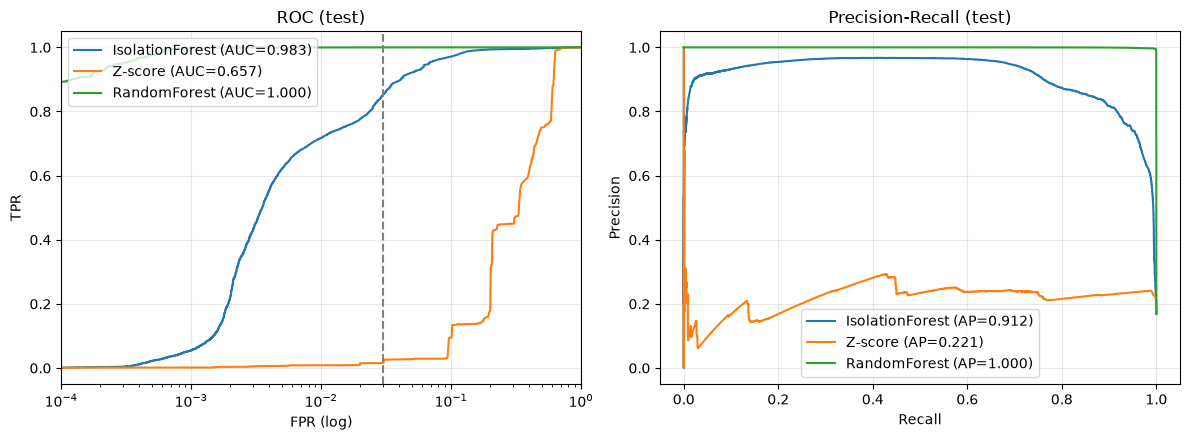

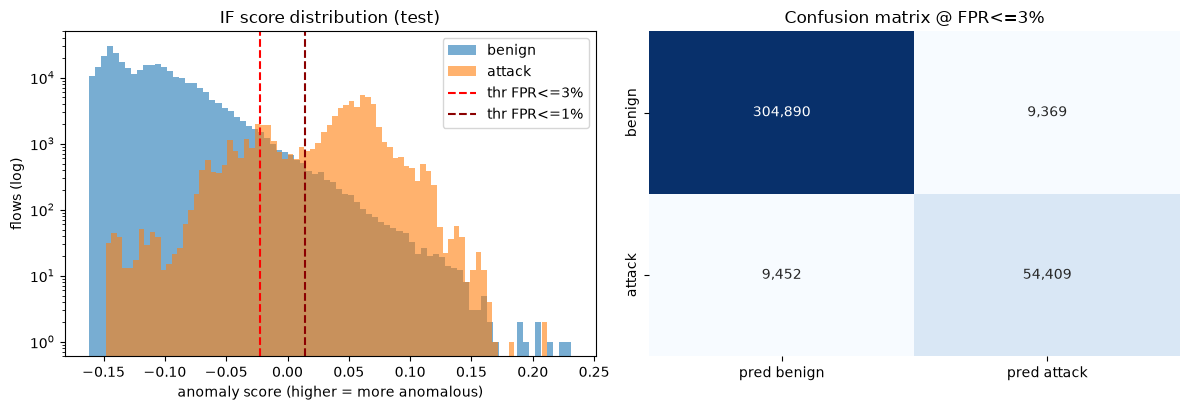

In [26]:
# ---- ROC / PR / score distribution / confusion matrix (test) ----
systems_test = {"IsolationForest": s_test0, "Z-score": z_test, "RandomForest": rf_test}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, s in systems_test.items():
    f_, t_, _ = roc_curve(yt, s); ax[0].plot(f_, t_, label=f"{name} (AUC={roc_auc_score(yt, s):.3f})")
    p_, r_, _ = precision_recall_curve(yt, s); ax[1].plot(r_, p_, label=f"{name} (AP={average_precision_score(yt, s):.3f})")
ax[0].set(xscale="log", xlim=(1e-4, 1), xlabel="FPR (log)", ylabel="TPR", title="ROC (test)"); ax[0].axvline(0.03, ls="--", c="gray")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (test)")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(EXP_DIR / "figures" / "roc_pr_test.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(s_test0[yt == 0], bins=80, alpha=0.6, label="benign", log=True)
ax[0].hist(s_test0[yt == 1], bins=80, alpha=0.6, label="attack", log=True)
for op, c in (("FPR<=3%", "red"), ("FPR<=1%", "darkred")):
    ax[0].axvline(thr_if0[op], c=c, ls="--", label=f"thr {op}")
ax[0].set(xlabel="anomaly score (higher = more anomalous)", ylabel="flows (log)", title="IF score distribution (test)"); ax[0].legend()
cm = confusion_matrix(yt, pred_if0, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[1], xticklabels=["pred benign", "pred attack"], yticklabels=["benign", "attack"])
ax[1].set_title(f"Confusion matrix @ {DEPLOY_OP}")
plt.tight_layout(); plt.savefig(EXP_DIR / "figures" / "scores_confusion.png", dpi=150); plt.show()

Per-family recall at FPR<=3% (thresholds from validation):


,support,IsolationForest,Z-score,RandomForest,Hybrid
BENIGN (=FPR),314259,0.030,0.030,0.031,0.029
DoS Hulk,25927,0.883,0.001,1.000,1.000
DDoS,19202,0.957,0.000,1.000,1.000
PortScan,13604,0.770,0.003,1.000,1.000
DoS GoldenEye,1543,0.458,0.246,1.000,1.000
FTP-Patator,890,0.666,0.000,1.000,1.000
DoS slowloris,808,0.964,0.550,0.998,0.998
DoS Slowhttptest,784,0.705,0.115,1.000,1.000
SSH-Patator,483,0.012,0.000,1.000,1.000
Bot,292,0.045,0.000,0.997,0.990


Macro-average recall over attack families:


,IsolationForest,Z-score,RandomForest,Hybrid
macro recall,0.539,0.144,0.999,0.998


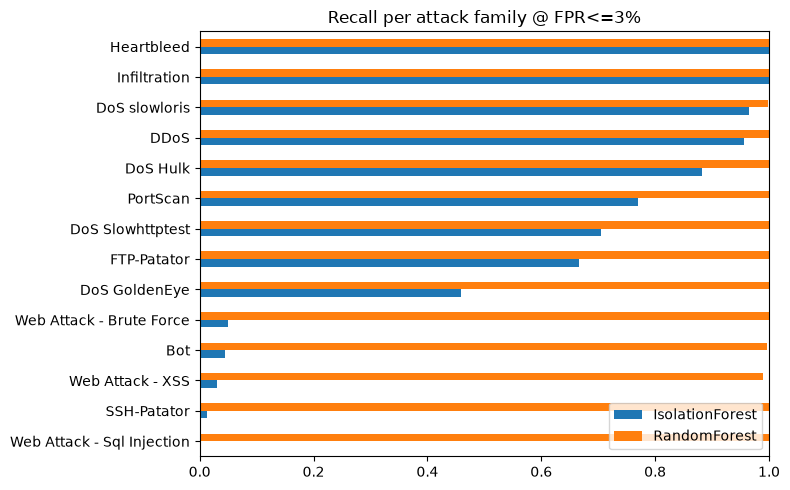

In [27]:
# ---- Per-family recall ----
fam = m_test["label"].to_numpy()
preds_dep = {"IsolationForest": pred_if0,
             "Z-score": z_test >= thr_z[DEPLOY_OP],
             "RandomForest": rf_test >= thr_rf[DEPLOY_OP],
             "Hybrid": hybrid_pred(FPR_BUDGETS[DEPLOY_OP])}
fam_tbl = pd.DataFrame({"support": pd.Series(fam).value_counts(),
                        **{k: pd.Series(v).groupby(fam).mean() for k, v in preds_dep.items()}})
fam_tbl = fam_tbl.rename(index={"BENIGN": "BENIGN (=FPR)"}).sort_values("support", ascending=False)
print(f"Per-family recall at {DEPLOY_OP} (thresholds from validation):")
display(fam_tbl.round(3))

attacks_only = fam_tbl.drop(index="BENIGN (=FPR)")
print("Macro-average recall over attack families:")
display(attacks_only[list(preds_dep)].mean().round(3).to_frame("macro recall").T)
attacks_only[["IsolationForest", "RandomForest"]].sort_values("IsolationForest").plot.barh(figsize=(8, 5), title=f"Recall per attack family @ {DEPLOY_OP}")
plt.xlim(0, 1); plt.tight_layout(); plt.savefig(EXP_DIR / "figures" / "per_family_recall.png", dpi=150); plt.show()

In [28]:
# ---- Per-day breakdown (Isolation Forest) ----
day = m_test["day"].to_numpy()
day_rows = []
for d in ["monday", "tuesday", "wednesday", "thursday", "friday"]:
    msk = day == d
    if msk.sum() == 0: continue
    yd, pdd = yt[msk], pred_if0[msk]
    day_rows.append({"day": d, "flows": int(msk.sum()), "attacks": int(yd.sum()),
                     "recall": pdd[yd == 1].mean() if yd.sum() else np.nan, "FPR": pdd[yd == 0].mean()})
display(pd.DataFrame(day_rows).round(4))

# ---- Base-rate analysis: precision collapses when attacks are rare (proposal: < 3% of traffic) ----
def precision_at_prevalence(tpr, fpr, prev):
    return tpr * prev / (tpr * prev + fpr * (1 - prev) + 1e-12)

EPS, PREV_OPS = 300, 0.03
prev_rows = []
for op in ["max-F1", *FPR_BUDGETS]:
    r = evaluate_at(yt, s_test0, thr_if0[op])
    row = {"op": op, "recall": r["recall"], "fpr": r["fpr"]}
    for prev in (yt.mean(), 0.03, 0.01, 0.001):
        row[f"precision @ {prev:.1%} attacks"] = precision_at_prevalence(r["recall"], r["fpr"], prev)
    row[f"false alerts / hour ({EPS} EPS, {PREV_OPS:.0%} attacks)"] = EPS * 3600 * (1 - PREV_OPS) * r["fpr"]
    prev_rows.append(row)
print("Isolation Forest - what the test numbers mean in a realistic network:")
display(pd.DataFrame(prev_rows).round(4))

,day,flows,attacks,recall,FPR
0,monday,75416,0,NaN,0.0294
1,tuesday,61340,1373,0.4363,0.0312
2,wednesday,88659,29064,0.8580,0.0317
3,thursday,60301,326,0.0583,0.0261
4,friday,92404,33098,0.8717,0.0307


Isolation Forest - what the test numbers mean in a realistic network:


,op,recall,fpr,precision @ 16.9% attacks,precision @ 3.0% attacks,precision @ 1.0% attacks,precision @ 0.1% attacks,"false alerts / hour (300 EPS, 3% attacks)"
0,max-F1,0.8822,0.0345,0.8388,0.4420,0.2055,0.0250,36092.4117
1,FPR<=3%,0.8520,0.0298,0.8531,0.4692,0.2240,0.0278,31232.0869
2,FPR<=1%,0.7171,0.0099,0.9365,0.6917,0.4228,0.0677,10357.3587
3,FPR<=0.1%,0.0450,0.0008,0.9165,0.6255,0.3529,0.0513,873.3917


# packaging — model bundle, confidence score, size and latency

<!-- The bundle is an `IFDetector` (see `src/ids_preprocess.py`): fitted `Pipeline(prep → IsolationForest)`, **all** operating-point
thresholds (the backend can expose them as sensitivity levels), the benign-score reference used for the **confidence score**
(FR03), and the **model version** (FR15). `n_jobs` is set to 1 for serving: thread start-up costs more than scoring a
micro-batch. -->

In [29]:
model0.n_jobs = 1
pipe = Pipeline([("prep", prep), ("iforest", model0)])
benign_ref = np.sort(s_val0[yv == 0])

dep_mean = {k: float(v) for k, v in if_mean.loc[DEPLOY_OP].items()}
detector = IFDetector(
    pipe=pipe, thresholds={k: float(v) for k, v in thr_if0.items()}, default_op=DEPLOY_OP, benign_ref_sorted=benign_ref,
    features=prep.features, model_version="iforest-0.1.0",
    meta={"variant": BEST_VARIANT, "if_params": {k: (float(v) if isinstance(v, float) else v) for k, v in IF_PARAMS.items()},
          "log_cols": prep.log_cols_, "seeds": SEEDS, "train_benign_rows": int(len(Xtr_b)), "dataset": "CICIDS2017",
          "test_metrics_mean_over_seeds_at_default_op": dep_mean, "sklearn": sklearn.__version__,
          "created": dt.datetime.now().isoformat(timespec="seconds")})

bundle_path = MODELS_DIR / "iforest_v0.1.0.joblib"
joblib.dump(detector, bundle_path)
print(f"Saved {bundle_path} | {bundle_path.stat().st_size / 1e6:.1f} MB")

# ---- reload test: the served model must reproduce the notebook scores exactly ----
det = joblib.load(bundle_path)
chk = det.predict(X_test.iloc[:2000])
print("reload reproduces notebook scores:", np.allclose(chk["anomaly_score"].to_numpy(), s_test0[:2000], atol=1e-5))
display(chk.head())

Saved ..\models\iforest_v0.1.0.joblib | 489.0 MB
reload reproduces notebook scores: True


,anomaly_score,is_anomaly,confidence,model_version
1951887,-0.157902,False,0.026793,iforest-0.1.0
1530354,-0.119398,False,0.484043,iforest-0.1.0
1690613,-0.106751,False,0.607932,iforest-0.1.0
43518,0.051810,True,0.996872,iforest-0.1.0
2102002,0.061804,True,0.997664,iforest-0.1.0


In [30]:
# ---- inference latency (raw DataFrame in -> score + decision + confidence out) ----
lat_rows = []
for bs, reps in [(1, 100), (32, 50), (256, 30), (1024, 10)]:
    batch = X_test.iloc[:bs]
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); det.predict(batch); ts.append((time.perf_counter() - t0) * 1000)
    lat_rows.append({"batch": bs, "p50 ms / call": np.percentile(ts, 50), "p95 ms / call": np.percentile(ts, 95),
                     "p50 ms / event": np.percentile(ts, 50) / bs})
lat = pd.DataFrame(lat_rows)
display(lat.round(3))

,batch,p50 ms / call,p95 ms / call,p50 ms / event
0,1,20.046,35.963,20.046
1,32,20.912,29.765,0.653
2,256,26.752,28.196,0.105
3,1024,42.664,48.299,0.042


In [31]:
# ---- acceptance check against the proposal (NFR-PERF-004 / TA02 / M04) ----
dep = if_mean.loc[DEPLOY_OP]
lat256 = float(lat.loc[lat["batch"] == 256, "p50 ms / event"].iloc[0])
lat1 = float(lat.loc[lat["batch"] == 1, "p50 ms / call"].iloc[0])
z_f1 = float(others[(others["system"] == "Z-score (non-ML)") & (others["op"] == DEPLOY_OP)]["f1"].iloc[0])

checks = pd.DataFrame([
    ("Precision >= 85%",                          dep["precision"], TARGETS["precision"], dep["precision"] >= TARGETS["precision"]),
    ("Recall >= 80%",                             dep["recall"],    TARGETS["recall"],    dep["recall"] >= TARGETS["recall"]),
    ("F1 >= 80%",                                 dep["f1"],        TARGETS["f1"],        dep["f1"] >= TARGETS["f1"]),
    ("FPR < 3%",                                  dep["fpr"],       TARGETS["fpr_max"],   dep["fpr"] < TARGETS["fpr_max"]),
    ("Latency per event, micro-batch 256 (ms) < 5", lat256,         TARGETS["latency_ms"], lat256 < TARGETS["latency_ms"]),
    ("Latency of a single-event call (ms) < 5",   lat1,             TARGETS["latency_ms"], lat1 < TARGETS["latency_ms"]),
    ("F1 beats the non-ML Z-score baseline",      dep["f1"],        z_f1,                 dep["f1"] > z_f1),
], columns=["criterion", "value", "target", "pass"])
checks["pass"] = checks["pass"].map({True: "PASS", False: "FAIL"})
print(f"Isolation Forest @ {DEPLOY_OP}, mean of {len(SEEDS)} seeds, TEST set:")
display(checks.round(4))

Isolation Forest @ FPR<=3%, mean of 5 seeds, TEST set:


,criterion,value,target,pass
0,Precision >= 85%,0.8491,0.8500,FAIL
1,Recall >= 80%,0.8301,0.8000,PASS
2,F1 >= 80%,0.8394,0.8000,PASS
3,FPR < 3%,0.0300,0.0300,PASS
4,"Latency per event, micro-batch 256 (ms) < 5",0.1045,5.0000,PASS
5,Latency of a single-event call (ms) < 5,20.0463,5.0000,FAIL
6,F1 beats the non-ML Z-score baseline,0.8394,0.0266,PASS


# robustness — unseen attack families (temporal split)

<!-- The random split above answers *"does it work on traffic that looks like what it was trained on?"*. The real promise of
an anomaly detector is different: **attacks that were never seen**. CICIDS2017 is organised by weekday, so we train on
Monday–Wednesday (benign + FTP/SSH-Patator + DoS family + Heartbleed) and test on Thursday–Friday (Web attacks, Infiltration,
Bot, PortScan, DDoS) – families that **none** of the models has seen. Thresholds come from a held-out slice of the *seen*
days only (the same budget as the deployed operating point). -->

In [32]:
if RUN_TEMPORAL_CHECK:
    seen_days = ["monday", "tuesday", "wednesday"]
    is_seen = meta["day"].isin(seen_days).to_numpy()
    seen_pos, unseen_pos = np.where(is_seen)[0], np.where(~is_seen)[0]
    tr_pos, va_pos = train_test_split(seen_pos, test_size=0.2, random_state=SEED, stratify=meta["label"].iloc[seen_pos])

    prep_t = FlowPreprocessor(features=feature_sets[BEST_FS], log_cols=None if BEST_USE_LOG else []).fit(X.iloc[tr_pos])
    Xtr_t, Xva_t, Xte_t = (prep_t.transform(X.iloc[p]) for p in (tr_pos, va_pos, unseen_pos))
    ytr_t, yva_t, yte_t = (y.iloc[p].to_numpy() for p in (tr_pos, va_pos, unseen_pos))
    fam_t = meta["label"].iloc[unseen_pos].to_numpy()
    print(f"train(seen) {Xtr_t.shape} | val(seen) {Xva_t.shape} | test(UNSEEN days) {Xte_t.shape}")

    if_t = IsolationForest(**IF_PARAMS, random_state=SEED, n_jobs=N_JOBS).fit(Xtr_t[ytr_t == 0])
    rf_t = RandomForestClassifier(**RF_PARAMS, n_jobs=N_JOBS, random_state=SEED).fit(Xtr_t, ytr_t)
    z_t = RobustZScoreDetector().fit(Xtr_t[ytr_t == 0])

    S = {"IsolationForest": (anomaly_scores(if_t, Xva_t), anomaly_scores(if_t, Xte_t)),
         "Z-score": (z_t.score(Xva_t), z_t.score(Xte_t)),
         "RandomForest": (rf_t.predict_proba(Xva_t)[:, 1], rf_t.predict_proba(Xte_t)[:, 1])}
    budget = FPR_BUDGETS[DEPLOY_OP]
    pred_t = {k: sv_te[1] >= threshold_at_fpr(yva_t, sv_te[0], budget) for k, sv_te in S.items()}
    ta, tb = threshold_at_fpr(yva_t, S["IsolationForest"][0], budget / 2), threshold_at_fpr(yva_t, S["RandomForest"][0], budget / 2)
    pred_t["Hybrid"] = (S["IsolationForest"][1] >= ta) | (S["RandomForest"][1] >= tb)

    tbl_t = pd.DataFrame({"support": pd.Series(fam_t).value_counts(), **{k: pd.Series(v).groupby(fam_t).mean() for k, v in pred_t.items()}})
    tbl_t = tbl_t.rename(index={"BENIGN": "BENIGN (=FPR)"}).sort_values("support", ascending=False)
    print(f"Recall on UNSEEN attack families, thresholds from seen-days validation ({DEPLOY_OP}):")
    display(tbl_t.round(3))
    macro = tbl_t.drop(index="BENIGN (=FPR)")[list(pred_t)].mean().round(3)
    print("Macro recall over unseen families:")
    display(macro.to_frame("macro recall").T)
    overall_t = pd.DataFrame({k: {m: evaluate_pred(yte_t, p)[m] for m in ("precision", "recall", "f1", "fpr")} for k, p in pred_t.items()}).T
    print("Overall on the unseen days (all attack families pooled):")
    display(overall_t.round(3))

train(seen) (1202344, 27) | val(seen) (300586, 27) | test(UNSEEN days) (1017868, 27)
Recall on UNSEEN attack families, thresholds from seen-days validation (FPR<=3%):


,support,IsolationForest,Z-score,RandomForest,Hybrid
BENIGN (=FPR),795033,0.118,0.023,0.071,0.110
DDoS,128014,0.964,0.000,0.974,0.949
PortScan,90694,0.999,0.003,0.049,1.000
Bot,1948,0.274,0.000,0.031,0.274
Web Attack - Brute Force,1470,0.049,0.000,0.965,0.954
Web Attack - XSS,652,0.026,0.000,0.992,0.989
Infiltration,36,0.917,0.278,0.333,0.889
Web Attack - Sql Injection,21,0.000,0.000,1.000,0.905


Macro recall over unseen families:


,IsolationForest,Z-score,RandomForest,Hybrid
macro recall,0.461,0.04,0.621,0.851


Overall on the unseen days (all attack families pooled):


,precision,recall,f1,fpr
IsolationForest,0.696,0.964,0.808,0.118
Z-score,0.016,0.001,0.002,0.023
RandomForest,0.700,0.589,0.640,0.071
Hybrid,0.711,0.964,0.819,0.110


In [33]:
# ---- export everything needed for the report ----
summary.to_csv(EXP_DIR / "final_results.csv", index=False)
fam_tbl.to_csv(EXP_DIR / "per_family_recall.csv")
checks.to_csv(EXP_DIR / "acceptance_check.csv", index=False)
print("Exported ->", EXP_DIR.resolve())
print("Bundle   ->", bundle_path.resolve())
print("Features ->", (CONFIG_DIR / "features.json").resolve())

Exported -> C:\Users\user\Documents\study\college\GP\Grad-Project\network-anomaly-detection\experiments
Bundle   -> C:\Users\user\Documents\study\college\GP\Grad-Project\network-anomaly-detection\models\iforest_v0.1.0.joblib
Features -> C:\Users\user\Documents\study\college\GP\Grad-Project\network-anomaly-detection\configs\features.json
